# 03 · Predicting the future: the growth model and the value model

A club doesn't buy a player for what he did last season. It buys him for what he'll do in the **next** seasons.
In this notebook we build two models:

1. **Growth model:** predicts a player's overall rating **two seasons later**. This is the "future" part of the Finder.
2. **Value model:** predicts what a player *should* cost given his rating, age and role. The difference from his real
   price tells us whether he is cheap or expensive. This is the "price" part.

For both we ask the same question: **is the model better than a simple rule?** A model that can't beat
"assume nothing changes" isn't worth using.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))   # our own modules live in src/
import plot_style
from plot_style import BLUE, ORANGE, AQUA, INK_2, MUTED, EURO, euro

plot_style.apply()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression

from finder import GROWTH_FEATURES, growth_pairs, load_players, train_growth_model, value_residuals

players = load_players()
pairs = growth_pairs(players)   # every player-season joined with the same player two seasons later

## 1. The growth model

### Setting up a fair test (no peeking into the future)

The most common mistake in prediction projects is **data leakage**: the model accidentally learns from information
it would not have in real life. Then it looks great in testing and fails in practice.

For us, the danger is time. If we mixed all seasons and split them randomly, the model could train on FIFA 21 → 23
and be tested on FIFA 19 → 21. It would then "know" about trends that happened after the test date.

So we split **by time**:

- **Training:** seasons FIFA 15–17, with their outcomes two seasons later (FIFA 17–19).
- **Testing:** seasons FIFA 19 and 20, with outcomes in FIFA 21 and 22.

Everything the model learns was known by summer 2019, and it's tested on decisions made in 2019 and 2020.
This is exactly the function `train_growth_model(players, decision_version=19)` in `src/finder.py`: it only uses
pairs where the "two seasons later" is already in the past at the decision date.

One more detail: we can only learn from players who are **still in the game** two years later (otherwise there's no
"after" rating). So the model answers "how good will he be, *if he's still playing at this level*?" We deal with the
players who disappear in the backtest (notebook 04).

In [2]:
known = pairs[pairs.overall_2y.notna()]
test = known[known.fifa_version.isin([19, 20])]
train = known[known.fifa_version <= 17]
print(f"Training rows: {len(train):,}   Test rows: {len(test):,}")

Training rows: 39,123   Test rows: 28,113


### Three ways to predict

We compare three methods, from the simplest to the most complex:

1. **No change:** the rating in two years equals the rating today. It sounds naive, but ratings change slowly, so this
   is a strong baseline.
2. **Linear regression on overall, potential and age:** a straight-line formula. It can learn simple rules like
   "young players with high potential grow".
3. **Gradient boosting with all features:** many small decision trees, each one correcting the mistakes of the previous
   ones. It can learn complex patterns such as "fast young wingers in strong leagues grow more". We use scikit-learn's
   `HistGradientBoostingRegressor`, which is fast on large tables and handles missing values by itself.

We measure the **MAE (mean absolute error)**: on average, how many rating points the prediction is off.

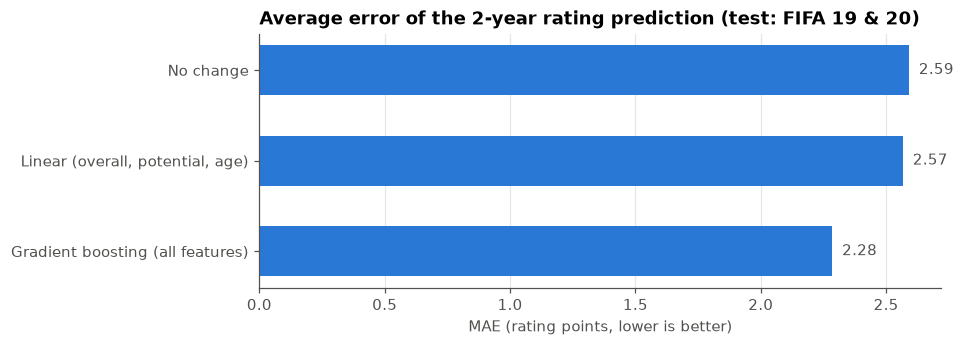

In [3]:
linear = LinearRegression().fit(train[["overall", "potential", "age"]], train.overall_2y)
boosting = train_growth_model(players, decision_version=19)

predictions = {
    "No change": test.overall.to_numpy(),
    "Linear (overall, potential, age)": linear.predict(test[["overall", "potential", "age"]]),
    "Gradient boosting (all features)": boosting.predict(test[GROWTH_FEATURES]),
}
mae = {name: np.mean(np.abs(test.overall_2y - p)) for name, p in predictions.items()}

fig, ax = plt.subplots(figsize=(8, 3))
names = list(mae)[::-1]
ax.barh(names, [mae[n] for n in names], color=BLUE, height=0.55)
for n in names:
    ax.text(mae[n], n, f"  {mae[n]:.2f}", va="center", color=INK_2)
ax.grid(axis="y", visible=False)
ax.set(title="Average error of the 2-year rating prediction (test: FIFA 19 & 20)", xlabel="MAE (rating points, lower is better)")
plt.show()

Gradient boosting is clearly the best. Its average error is about 2.3 points, while "no change" is off by about 2.6.
That's roughly **13% smaller error**. The linear model is only slightly better than doing nothing: overall, potential
and age alone aren't enough.

### Does it rank players correctly?

For scouting, the exact number matters less than the **order**: we want to know *which* players will grow the most.
We use the **Spearman correlation** between predicted growth and real growth. It only looks at the ranking:
1 means a perfect order, 0 means a random order.

The natural competitor is EA's own `potential` rating. "Potential minus overall" is EA's guess of how much a player will
grow. Can our model rank growth better than EA's built-in guess?

In [4]:
real_growth = test.overall_2y - test.overall
young = (test.age <= 23).to_numpy()
growth_guesses = {
    "EA potential − overall": (test.potential - test.overall).to_numpy(),
    "Linear model": predictions["Linear (overall, potential, age)"] - test.overall.to_numpy(),
    "Gradient boosting": predictions["Gradient boosting (all features)"] - test.overall.to_numpy(),
}
pd.DataFrame({
    "all players": {n: spearmanr(g, real_growth).statistic for n, g in growth_guesses.items()},
    "players aged ≤ 23": {n: spearmanr(g[young], real_growth[young]).statistic for n, g in growth_guesses.items()},
}).round(3)

,all players,players aged ≤ 23
EA potential − overall,0.511,0.351
Linear model,0.563,0.416
Gradient boosting,0.569,0.422


Both models rank future growth clearly better than EA's potential, especially for young players (0.42 vs 0.35), which
is exactly the group where scouting decisions are hardest. EA's potential is one of the inputs, so the models don't throw
that knowledge away. They correct it, mostly by learning how much potential to trust at each age.

For *ranking*, the linear model is almost as good as boosting. Boosting's advantage is in the *size* of the prediction
(the MAE above). We keep boosting because the Finder uses both: the ranking to choose players and the predicted rating
to show the club how good the player will be.

### Does the model understand careers?

Let's compare the median predicted growth with the median real growth at each age:

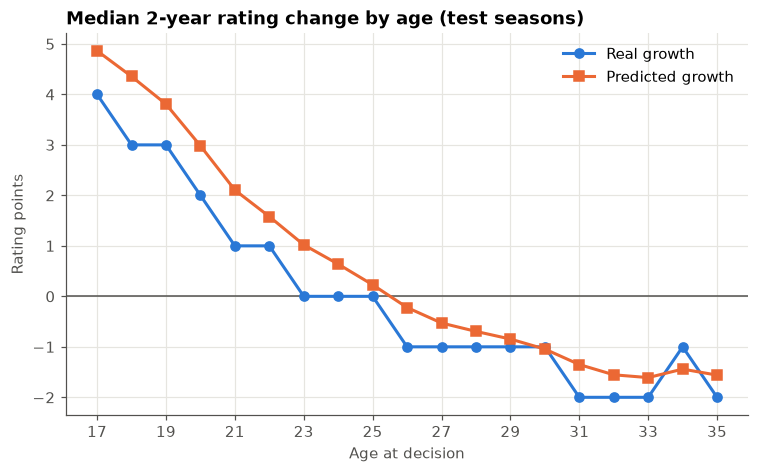

In [5]:
by_age = pd.DataFrame({
    "age": test.age,
    "real": real_growth,
    "predicted": predictions["Gradient boosting (all features)"] - test.overall.to_numpy(),
}).query("17 <= age <= 35").groupby("age").median()

fig, ax = plt.subplots()
ax.axhline(0, color=INK_2, lw=1)
ax.plot(by_age.index, by_age.real, color=BLUE, lw=2, marker="o", ms=6, label="Real growth")
ax.plot(by_age.index, by_age.predicted, color=ORANGE, lw=2, marker="s", ms=6, label="Predicted growth")
ax.set(title="Median 2-year rating change by age (test seasons)", xlabel="Age at decision", ylabel="Rating points")
ax.set_xticks(range(17, 36, 2))
ax.legend()
plt.show()

The model has learned the career curve: big growth for teenagers, around zero in the late twenties, and decline after 30.
The predicted line is smoother because the model gives decimal predictions, while real changes are whole numbers.

But there's also a **systematic gap**: up to about age 29, the orange line is 0.5–1 point *above* the blue one, so the model
is a bit **too optimistic** for these test years. A likely reason is that EA changed how it rates players over time:
players in FIFA 15–17 (the training years) grew a little faster than players in FIFA 19–22. This is a form of **outdated data**,
one of the pitfalls in the task. For the Finder it matters little, because the gap is about the same for everyone, so the
*order* of candidates doesn't change. When we tell the club "he will be rated 78", we should say "about 77–78".

### What does the model look at?

**Permutation importance** answers "how much worse does the model get if we scramble one feature?" We shuffle one
column randomly (so it carries no information), measure how much the error grows, and repeat for every feature.
A big increase means the model relies on that feature a lot.

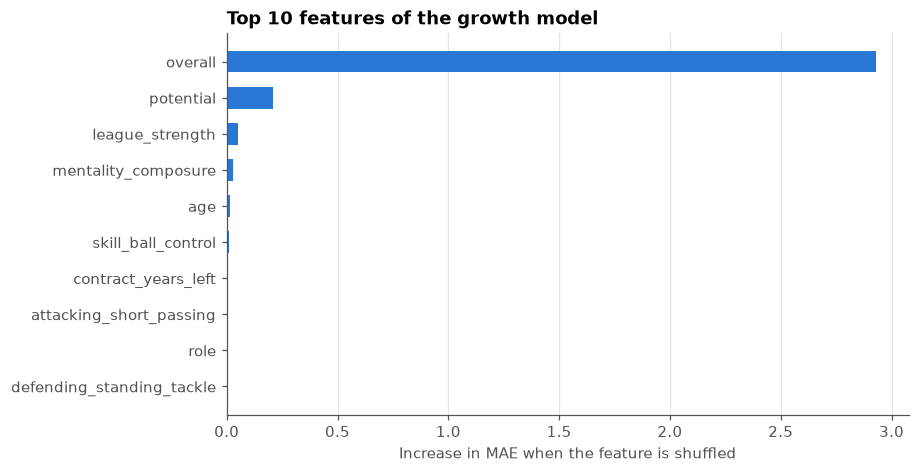

In [6]:
sample = test.sample(5000, random_state=0)
imp = permutation_importance(boosting, sample[GROWTH_FEATURES], sample.overall_2y,
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=GROWTH_FEATURES).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.grid(axis="y", visible=False)
ax.set(title="Top 10 features of the growth model", xlabel="Increase in MAE when the feature is shuffled")
plt.show()

The current rating dominates by far, which makes sense: the best predictor of the future rating is today's rating.
Then come EA's potential and the strength of the league. Age is low on the list, but not because age is unimportant:
"potential minus overall" already carries most of the age information (young players have big gaps), so scrambling age
alone hurts little. Permutation importance measures what a feature adds **on top of** the others.

This is a sanity check: the model relies on football-sensible information, not on some strange artifact of the data.

### Example: who did the model expect to grow, and what happened?

Here are the 10 players with the highest predicted growth at the end of FIFA 20 (summer 2020), among players already
rated 65 or more, together with what actually happened by FIFA 22. Remember the model was trained only on data up to
2019 and has never seen these outcomes.

In [7]:
season20 = test[(test.fifa_version == 20) & (test.overall >= 65)].copy()
season20["predicted_2y"] = boosting.predict(season20[GROWTH_FEATURES])
season20["predicted_growth"] = season20.predicted_2y - season20.overall
season20["real_growth"] = season20.overall_2y - season20.overall
cols = ["short_name", "age", "club_name", "overall", "potential", "predicted_2y", "overall_2y", "real_growth"]
season20.nlargest(10, "predicted_growth")[cols].round(1)

,short_name,age,club_name,overall,potential,predicted_2y,overall_2y,real_growth
127792,Rodrigo Fernandes,18.0,Sporting CP,66.0,84.0,71.7,68.0,2.0
124874,Unai Vencedor,18.0,Athletic Club,66.0,84.0,71.7,76.0,10.0
126240,J. Gvardiol,17.0,Dinamo Zagreb,67.0,85.0,72.2,79.0,12.0
128255,Vítor Ferreira,19.0,Porto,67.0,84.0,72.1,78.0,11.0
122955,J. Garner,18.0,Manchester United,66.0,85.0,71.1,70.0,4.0
125178,S. Esposito,16.0,Inter,67.0,87.0,71.9,70.0,3.0
122950,David Tavares,20.0,Benfica,66.0,79.0,70.9,65.0,-1.0
126740,Eduardo Quaresma,17.0,Sporting CP,65.0,81.0,69.9,71.0,6.0
122360,C. Jones,18.0,Liverpool,65.0,85.0,69.9,75.0,10.0
127919,Reinier,17.0,Real Madrid,72.0,90.0,76.8,70.0,-2.0


## 2. The value model: are there bargains hidden in EA's prices?

The second classic Moneyball idea: two players with the same rating, age and role should cost about the same. If one is
much cheaper, maybe the market is missing something.

We train a gradient boosting model to predict **log(market value)** from overall, potential, age, international reputation,
contract length and role. (We use the log because values are extremely skewed, see notebook 01.) The difference
*expected log value − real log value* is the **undervaluation**: positive means cheaper than expected.

Two important choices:

- **We deliberately leave the league out.** If buying in "cheap leagues" is a real opportunity, we want it to show up as
  undervaluation.
- **Out-of-fold predictions.** We split the season's players into 5 parts. Each part is priced by a model trained on the
  other 4. So no player is judged by a model that already saw his own price.

We use the FIFA 20 season (summer 2020).

In [8]:
season = pairs[pairs.fifa_version == 20].copy()
season["undervaluation"] = value_residuals(season)
priced = season.dropna(subset=["undervaluation"])
pricing_error = np.abs(np.exp(-priced.undervaluation) - 1)
print(f"Typical (median) pricing error: {pricing_error.median():.1%}")
print(f"90% of players are priced within: {pricing_error.quantile(0.9):.1%}")

Typical (median) pricing error: 1.6%
90% of players are priced within: 4.3%


This is a surprise. With only six simple features, the model predicts EA's price almost perfectly: typically within
about 2%. That means **EA's market value is essentially a formula** of rating, potential, age and role. There's
almost no room left for "hidden bargains" inside EA's prices.

Does the league really not matter? In notebook 01 we suspected the league price gaps were caused by age and potential
(confounding). Now we can check: if the league mattered, players from "cheap" leagues would come out as undervalued.

In [9]:
LEAGUES = {13: "England · Premier League", 53: "Spain · La Liga", 31: "Italy · Serie A",
           19: "Germany · Bundesliga", 16: "France · Ligue 1", 308: "Portugal · Liga Portugal",
           68: "Turkey · Süper Lig", 39: "USA · MLS", 349: "Japan · J-League"}
(priced[priced.league_id.isin(LEAGUES)]
 .assign(cheaper_than_expected=lambda d: 1 - np.exp(-d.undervaluation))
 .groupby("league_id")["cheaper_than_expected"].median()
 .rename(index=LEAGUES).sort_values().to_frame("median: cheaper than expected")
 .style.format("{:+.1%}"))

,median: cheaper than expected
league_id,
Japan · J-League,-0.1%
England · Premier League,-0.1%
France · Ligue 1,-0.1%
Portugal · Liga Portugal,-0.0%
Germany · Bundesliga,+0.0%
Spain · La Liga,+0.0%
USA · MLS,+0.1%
Italy · Serie A,+0.1%
Turkey · Süper Lig,+0.2%


Every league is within about ±0.2%. Once rating, potential and age are known, **the league doesn't change EA's price**.
The confounding suspicion from notebook 01 is confirmed.

### Does "undervalued" still mean "good deal"?

The remaining residuals are tiny, but let's test them anyway. We split players into five equal groups (**quintiles**), from
the most overvalued 20% to the most undervalued 20%, and look at how their market value changed by FIFA 22.

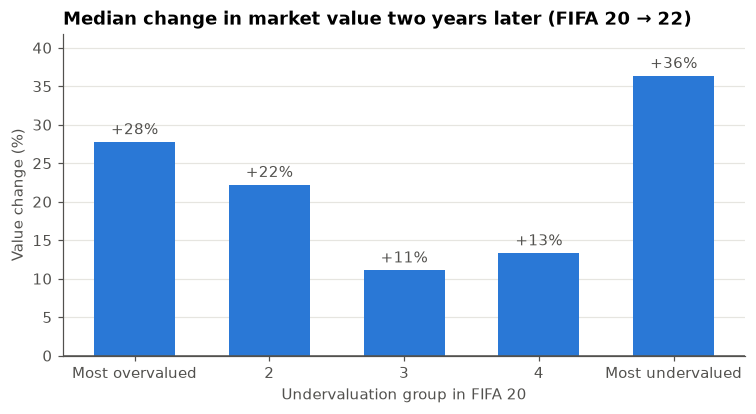

In [10]:
later = priced.dropna(subset=["value_eur_2y"]).copy()
later["value_change"] = np.log(later.value_eur_2y / later.value_eur)
later["quintile"] = pd.qcut(later.undervaluation, 5,
                            labels=["Most overvalued", "2", "3", "4", "Most undervalued"])
summary = later.groupby("quintile", observed=True).agg(
    players=("player_id", "size"),
    median_value_change=("value_change", lambda v: np.exp(v.median()) - 1),
)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(summary.index.astype(str), summary.median_value_change * 100, color=BLUE, width=0.6)
ax.axhline(0, color=INK_2, lw=1)
for i, v in enumerate(summary.median_value_change * 100):
    ax.text(i, v + 1, f"{v:+.0f}%", ha="center", color=INK_2)
ax.set_ylim(0, summary.median_value_change.max() * 115)
ax.grid(axis="x", visible=False)
ax.set(title="Median change in market value two years later (FIFA 20 → 22)",
       xlabel="Undervaluation group in FIFA 20", ylabel="Value change (%)")
plt.show()

There's no useful pattern: the bars don't go steadily up from "overvalued" to "undervalued". Instead both extreme groups
gain the most (a U-shape). The players with the biggest residuals are mostly those whose ratings EA was in the middle of
changing (often young, fast-moving players), so their price and rating were briefly out of sync. That's noise, not bargains.

### What this negative result teaches us

This is an honest **negative result**, and the task explicitly says negative results count. It tells us three things:

1. **EA prices can't show real-market bargains.** A real club pays real transfer fees, which depend on negotiations,
   contracts and demand. EA's value is a formula. To find real-market undervaluation, we'd need real fees (for example,
   Transfermarkt data). That's the most important limitation of using game data, and the task asks us to explain it.
2. **The only way to "beat" a formula price is to know the future better than the formula.** EA's price is based on
   today's rating, potential and age. If our growth model can spot players who will improve **more than EA's potential
   suggests** (and section 1 showed it ranks growth better than potential), then those players are cheap *for what they
   will become*. That's our Moneyball edge.
3. **So the Finder's "price" ingredient is simply "cheaper within the budget".** The club can choose how much to trade
   quality for savings. Notebook 04 measures what that trade costs.

## 3. Checklist: why can we trust these models?

| Risk | What we did |
|---|---|
| Data leakage (using the future) | Train only on seasons whose "2 years later" was already known at the decision date; test on later seasons |
| Overfitting (memorizing the training data) | All numbers above are measured on test seasons the model never saw |
| A model is not better than a simple rule | Compared with "no change", a linear model and EA's own potential; boosting wins on error and ranking |
| A player judges his own price | Out-of-fold predictions in the value model |
| A pattern is caused by a hidden factor | League price gaps checked with the value model: they vanish once age and potential are known |
| Outdated data / rating changes over time | Detected: the growth model is ~0.5–1 point optimistic in test years; ranking is unaffected |
| Players who disappear | Growth model only predicts "if still playing"; the backtest counts drop-outs as failures |

## Summary

| Model | Result | Role in the Finder |
|---|---|---|
| Growth model (gradient boosting) | MAE ≈ 2.3 vs 2.6 for "no change"; ranks growth better than EA potential, especially for young players | Main ranking signal ("future") |
| Value model (out-of-fold) | EA price ≈ a formula of rating, potential, age and role (≈2% error); residuals don't predict future value | Not used for ranking; "price" in the Finder = cheaper within the budget |

**Next:** notebook 04 combines style fit and the growth model into the Replacement Finder and tests it historically
against simple scouting rules.